# Assignment 3 · Part 2b — What the lot text adds
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

Notebook 05a produced text scores with transfer learning (three frozen encoders) and fine-tuning (rubert-tiny2).
This notebook puts them next to a model **without** transfer (TF-IDF) and answers the question that matters for the
project: **does the text improve the risk ranking of the tabular model**, and which way of using it works best?

| § | Content | A3 criterion |
|---|---|---|
| 1 | Setup, scores from 05a | — |
| 2 | Text alone: TF-IDF vs frozen encoders vs fine-tuned encoder, on seen and unseen texts | 3, 4 |
| 3 | Text inside the tabular model: embeddings as features, stacking, blending | 3, 4 |
| 4 | Conclusions | — |

**How to run:** run 05a first (it writes the scores this notebook reads); then `Kernel → Restart & Run All`
(≈ 5 minutes).

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy.sparse import hstack
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P

PROC = ROOT / "data" / "processed"; PRED = ROOT / "data" / "predictions"
FIG = ROOT / "figures"; RES = ROOT / "results" / "a3_05"; RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

df = P.load_model_table(ROOT)
df["text"] = df[P.TEXT_FEATURE].fillna("").str.lower().str.strip()
y = P.TARGET
for c in P.CAT_FEATURES: df[c] = df[c].astype("category")
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = train[y].to_numpy(), val[y].to_numpy(), test[y].to_numpy()
unseen = ~test.text.isin(set(train.text)).to_numpy()
print(f"test rows with a text never seen in train: {unseen.sum():,} ({unseen.mean():.1%})")

def load_scores(name):
    s = pd.read_parquet(PRED / f"{name}.parquet").set_index("id").score
    return s.loc[val.id].to_numpy(), s.loc[test.id].to_numpy()

rng = np.random.default_rng(SEED)
BOOT = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]
def boot_diff(p_new, p_ref):
    d = np.array([average_precision_score(y_te[i], p_new[i]) - average_precision_score(y_te[i], p_ref[i]) for i in BOOT])
    return f"{d.mean():+.3f} [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]"

def report(name, p_val, p_test):
    return {"model": name, "val PR-AUC": average_precision_score(y_va, p_val),
            "test PR-AUC": average_precision_score(y_te, p_test), "test ROC-AUC": roc_auc_score(y_te, p_test),
            "test PR-AUC, seen texts": average_precision_score(y_te[~unseen], p_test[~unseen]),
            "test PR-AUC, unseen texts": average_precision_score(y_te[unseen], p_test[unseen]),
            "test ROC-AUC, unseen texts": roc_auc_score(y_te[unseen], p_test[unseen])}

test rows with a text never seen in train: 8,707 (22.3%)


## 2. Text alone: does transfer learning beat a model without it?

**No transfer — TF-IDF + logistic regression.** Word uni-/bi-grams plus character 3–5-grams (character n-grams
handle Russian inflection: "ремонт", "ремонта", "ремонту"), class-weighted logistic regression. It knows nothing
about language beyond the training texts.

The other rows are read from 05a: a linear probe on each frozen encoder (transfer as-is) and the fine-tuned
rubert-tiny2 (transfer + adaptation).

In [2]:
w = TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True, max_features=50_000)
c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True, max_features=100_000)
Xtr = hstack([w.fit_transform(train.text), c.fit_transform(train.text)]).tocsr()
Xva, Xte = (hstack([w.transform(d.text), c.transform(d.text)]).tocsr() for d in (val, test))
tfidf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000).fit(Xtr, y_tr)
p_tfidf = (tfidf.predict_proba(Xva)[:, 1], tfidf.predict_proba(Xte)[:, 1])
del Xtr, Xva, Xte

text_rows = [report("TF-IDF + logistic regression (no transfer)", *p_tfidf)]
for key in ("rubert-tiny2", "multilingual-e5-small", "rubert-base-cased"):
    text_rows.append(report(f"frozen {key} + linear probe (transfer)", *load_scores(f"05_probe_{key}")))
text_rows.append(report("fine-tuned rubert-tiny2 (transfer + fine-tuning)", *load_scores("05_rubert_finetuned")))
text_alone = pd.DataFrame(text_rows).set_index("model"); text_alone

,val PR-AUC,test PR-AUC,test ROC-AUC,"test PR-AUC, seen texts","test PR-AUC, unseen texts","test ROC-AUC, unseen texts"
model,,,,,,
TF-IDF + logistic regression (no transfer),0.202,0.153,0.698,0.129,0.200,0.679
frozen rubert-tiny2 + linear probe (transfer),0.164,0.125,0.667,0.104,0.172,0.640
frozen multilingual-e5-small + linear probe (transfer),0.174,0.131,0.676,0.109,0.189,0.659
frozen rubert-base-cased + linear probe (transfer),0.172,0.133,0.681,0.110,0.187,0.655
fine-tuned rubert-tiny2 (transfer + fine-tuning),0.199,0.156,0.697,0.124,0.228,0.706


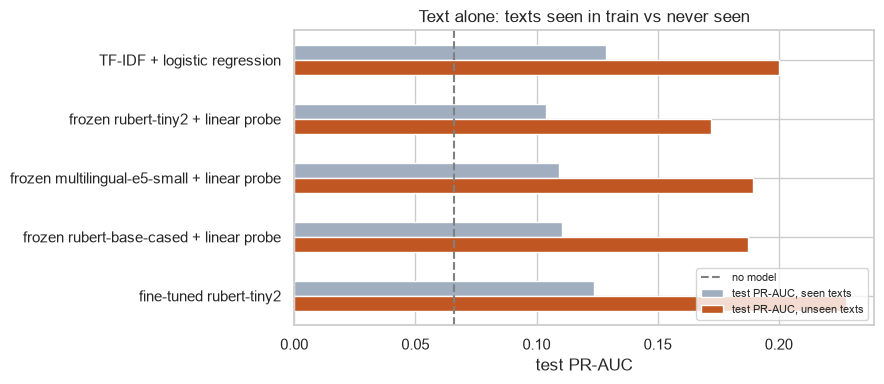

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = text_alone[["test PR-AUC, seen texts", "test PR-AUC, unseen texts"]]
plot.index = [i.split(" (")[0] for i in plot.index]
plot.plot.barh(ax=ax, color=["#a0aec0", "#c05621"])
ax.axvline(y_te.mean(), ls="--", color="grey", label="no model")
ax.set(xlabel="test PR-AUC", title="Text alone: texts seen in train vs never seen")
ax.legend(fontsize=8, loc="lower right"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "a3_05_text_alone.png", dpi=150, bbox_inches="tight"); plt.show()

The **unseen** column is the real test of understanding: there the model cannot recall the failure rate of a
template it has seen and must generalise from the words. A model that wins on seen texts but loses on unseen ones
has memorised, not understood.

## 3. Text inside the tabular model

The practical question is not whether text predicts failure on its own (it is weaker than the table: one cannot
judge a procurement by its name only), but whether it **adds** to the 20 tabular features. The tabular model is the
LightGBM with learning rate 0.05 and early stopping on validation — notebook 04 showed that tuning LightGBM brings
no gain on these features, and a fixed simple configuration keeps the comparison about the *features*. Three ways to
add text:

1. **Embeddings as features** — 32 principal components of the frozen vectors of each encoder (PCA fitted on train
   texts only), appended to the 20 features.
2. **Stacking** — the fine-tuned text score becomes one extra feature. On train it is the *out-of-fold* score from
   05a (each procurement scored by a model that never saw it); on validation and test, the score of the full model.
3. **Blending** — the scores of the tabular model and of the fine-tuned text model are averaged on the logit scale
   with a weight chosen on validation.

In [4]:
# Workhorse LightGBM for feature experiments (notebook 04: tuning LightGBM brings no gain on these features, and this
# configuration is as good as the best of 50 Optuna trials on validation while being stable and fast)
LGB = dict(learning_rate=0.05)

def fit_lgb(cols, tr=train):
    m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **LGB)
    m.fit(tr[cols], tr[y], eval_set=[(val[cols], y_va)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict_proba(val[cols])[:, 1], m.predict_proba(test[cols])[:, 1]

texts = pd.read_parquet(PROC / "emb_texts.parquet").text
tpos = pd.Series(np.arange(len(texts)), index=texts.values)
combo = {"LightGBM, 20 features": fit_lgb(P.FEATURES)}
for key in ("rubert-tiny2", "multilingual-e5-small", "rubert-base-cased"):
    E = np.load(PROC / f"emb_{key}.npy")
    pca = PCA(32, random_state=SEED).fit(E[tpos[train.text].to_numpy()])
    cols = [f"{key}_pc{k}" for k in range(32)]
    for d in (train, val, test):
        d[cols] = pca.transform(E[tpos[d.text].to_numpy()])
    combo[f"+ 32 components of frozen {key}"] = fit_lgb(P.FEATURES + cols)

In [5]:
oof = pd.read_parquet(PRED / "05_rubert_oof_train.parquet").set_index("id").score
ft_val, ft_test = load_scores("05_rubert_finetuned")
train["ft_score"] = oof.loc[train.id].to_numpy(); val["ft_score"] = ft_val; test["ft_score"] = ft_test
combo["+ fine-tuned text score (stacking)"] = fit_lgb(P.FEATURES + ["ft_score"])

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
base_val, base_test = combo["LightGBM, 20 features"]
weights = np.linspace(0, 1, 21)
val_curve = [average_precision_score(y_va, (1 - a) * logit(base_val) + a * logit(ft_val)) for a in weights]
alpha = float(weights[int(np.argmax(val_curve))])
combo[f"blend: tabular + fine-tuned text (weight {alpha:.2f} on validation)"] = (
    (1 - alpha) * logit(base_val) + alpha * logit(ft_val), (1 - alpha) * logit(base_test) + alpha * logit(ft_test))

ref = combo["LightGBM, 20 features"][1]
rows = []
for name, (pv, pt) in combo.items():
    r = report(name, pv, pt)
    r["Δ test PR-AUC vs 20 features"] = "" if name == "LightGBM, 20 features" else boot_diff(pt, ref)
    rows.append(r)
with_table = pd.DataFrame(rows).set_index("model"); with_table

,val PR-AUC,test PR-AUC,test ROC-AUC,"test PR-AUC, seen texts","test PR-AUC, unseen texts","test ROC-AUC, unseen texts",Δ test PR-AUC vs 20 features
model,,,,,,,
"LightGBM, 20 features",0.343,0.311,0.808,0.285,0.367,0.811,
+ 32 components of frozen rubert-tiny2,0.398,0.347,0.822,0.327,0.393,0.817,"+0.036 [+0.025, +0.048]"
+ 32 components of frozen multilingual-e5-small,0.393,0.339,0.820,0.313,0.390,0.822,"+0.028 [+0.017, +0.040]"
+ 32 components of frozen rubert-base-cased,0.392,0.336,0.822,0.316,0.382,0.820,"+0.025 [+0.015, +0.037]"
+ fine-tuned text score (stacking),0.380,0.333,0.814,0.309,0.388,0.817,"+0.022 [+0.011, +0.033]"
blend: tabular + fine-tuned text (weight 0.30 on validation),0.369,0.321,0.810,0.307,0.376,0.813,"+0.010 [+0.003, +0.018]"


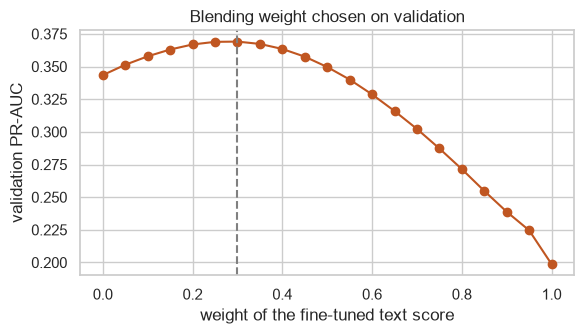

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(weights, val_curve, "o-", color="#c05621")
ax.axvline(alpha, ls="--", color="grey")
ax.set(xlabel="weight of the fine-tuned text score", ylabel="validation PR-AUC", title="Blending weight chosen on validation")
plt.tight_layout(); plt.savefig(FIG / "a3_05_blend_weight.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
text_alone.to_csv(RES / "text_alone.csv"); with_table.to_csv(RES / "text_in_tabular.csv")
for name, (pv, pt) in {**combo, "TF-IDF + logistic regression": p_tfidf}.items():
    key = "05b_" + "".join(ch if ch.isalnum() else "_" for ch in name.lower()).strip("_")[:60]
    pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
                  "score": np.r_[pv, pt]}).to_parquet(PRED / f"{key}.parquet", index=False)
_ = (RES / "blend_weight.json").write_text(json.dumps({"alpha": alpha}))

## 4. Conclusions

* **Transfer learning (criterion 4) — weak alone, strongest inside the table.** On its own, a linear probe on frozen
  encoder vectors loses to plain TF-IDF (test PR-AUC 0.125–0.133 vs 0.153; on unseen texts 0.17–0.19 vs 0.200):
  general-language similarity is not the same thing as procurement risk. Inside the tabular model the picture
  reverses: 32 principal components of the frozen rubert-tiny2 vectors add **+0.036 [+0.025, +0.048]** to the
  20-feature LightGBM (0.311 → 0.347), more than any other way of using the text. The vectors tell the tree model
  *what kind of purchase* this is, and the tree model combines that with value, method and competition. The smallest
  encoder is also the best here (+0.036 vs +0.028 / +0.025 for the 4–6 times larger ones).
* **Fine-tuning (criterion 3) — the best text model, not the best text feature.** The fine-tuned rubert-tiny2 is the
  best model of the text alone on procurements with unseen names (0.228 vs 0.200 for TF-IDF and 0.172 for the frozen
  probe) and ties TF-IDF overall (0.156 vs 0.153): adapting the encoder teaches it which words signal risk. But as a
  single stacked feature it adds less to the tabular model (+0.022) than the 32 frozen components, and blending the
  two scores adds least (+0.010). Compressing the text into one risk number throws away the information about the
  product that the tabular model can combine with the other features.
* **Decision for the final model:** the 32 frozen rubert-tiny2 components.

In [8]:
print("Text alone, test PR-AUC (seen / unseen):")
print(text_alone[["test PR-AUC", "test PR-AUC, seen texts", "test PR-AUC, unseen texts"]].round(3).to_string())
print("\nText inside the tabular model, test PR-AUC:")
print(with_table[["test PR-AUC", "Δ test PR-AUC vs 20 features"]].to_string())

Text alone, test PR-AUC (seen / unseen):
                                                        test PR-AUC  test PR-AUC, seen texts  test PR-AUC, unseen texts
model                                                                                                                  
TF-IDF + logistic regression (no transfer)                    0.153                    0.129                      0.200
frozen rubert-tiny2 + linear probe (transfer)                 0.125                    0.104                      0.172
frozen multilingual-e5-small + linear probe (transfer)        0.131                    0.109                      0.189
frozen rubert-base-cased + linear probe (transfer)            0.133                    0.110                      0.187
fine-tuned rubert-tiny2 (transfer + fine-tuning)              0.156                    0.124                      0.228

Text inside the tabular model, test PR-AUC:
                                                              test PR-AUC 